In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv('../data/credit_card.csv')
print(df.shape)
df.head()

(8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 8950
Number of columns: 18


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   str    
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHASES_TRX    

In [5]:
df.dtypes

CUST_ID                                 str
BALANCE                             float64
BALANCE_FREQUENCY                   float64
PURCHASES                           float64
ONEOFF_PURCHASES                    float64
INSTALLMENTS_PURCHASES              float64
CASH_ADVANCE                        float64
PURCHASES_FREQUENCY                 float64
ONEOFF_PURCHASES_FREQUENCY          float64
PURCHASES_INSTALLMENTS_FREQUENCY    float64
CASH_ADVANCE_FREQUENCY              float64
CASH_ADVANCE_TRX                      int64
PURCHASES_TRX                         int64
CREDIT_LIMIT                        float64
PAYMENTS                            float64
MINIMUM_PAYMENTS                    float64
PRC_FULL_PAYMENT                    float64
TENURE                                int64
dtype: object

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.474828,2081.531879,0.000000,128.281915,873.385231,2054.140036,19043.13856
BALANCE_FREQUENCY,8950.0,0.877271,0.236904,0.000000,0.888889,1.000000,1.000000,1.00000
PURCHASES,8950.0,1003.204834,2136.634782,0.000000,39.635000,361.280000,1110.130000,49039.57000
ONEOFF_PURCHASES,8950.0,592.437371,1659.887917,0.000000,0.000000,38.000000,577.405000,40761.25000
INSTALLMENTS_PURCHASES,8950.0,411.067645,904.338115,0.000000,0.000000,89.000000,468.637500,22500.00000
CASH_ADVANCE,8950.0,978.871112,2097.163877,0.000000,0.000000,0.000000,1113.821139,47137.21176
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.00000
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.202458,0.298336,0.000000,0.000000,0.083333,0.300000,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.00000
CASH_ADVANCE_FREQUENCY,8950.0,0.135144,0.200121,0.000000,0.000000,0.000000,0.222222,1.50000


In [7]:
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().sum() / len(df)) * 100
})

missing = missing[missing['Missing_Count'] > 0]

missing.sort_values(
    by='Missing_Percentage',
    ascending=False
)

,Missing_Count,Missing_Percentage
MINIMUM_PAYMENTS,313,3.497207
CREDIT_LIMIT,1,0.011173


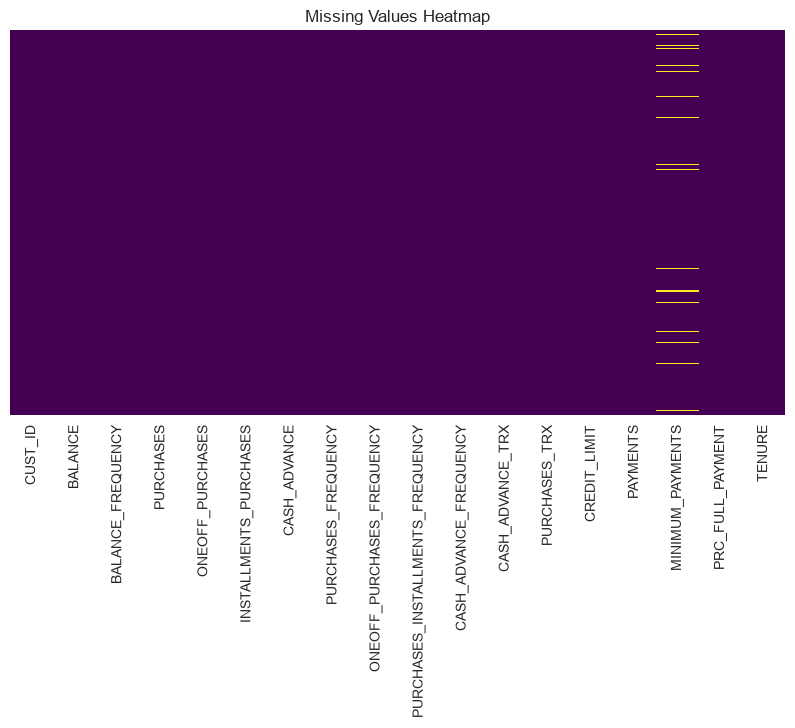

In [8]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title('Missing Values Heatmap')
plt.show()

In [9]:
print("Duplicate rows:", df.duplicated().sum())

print("Unique Customer IDs:", df['CUST_ID'].nunique())

Duplicate rows: 0
Unique Customer IDs: 8950


In [10]:
numeric_df = df.select_dtypes(include=np.number)

zero_counts = (numeric_df == 0).sum()

zero_counts.sort_values(ascending=False)


PRC_FULL_PAYMENT                    5903
CASH_ADVANCE_FREQUENCY              4628
CASH_ADVANCE                        4628
CASH_ADVANCE_TRX                    4628
ONEOFF_PURCHASES_FREQUENCY          4302
ONEOFF_PURCHASES                    4302
INSTALLMENTS_PURCHASES              3916
PURCHASES_INSTALLMENTS_FREQUENCY    3915
PURCHASES                           2044
PURCHASES_TRX                       2044
PURCHASES_FREQUENCY                 2043
PAYMENTS                             240
BALANCE                               80
BALANCE_FREQUENCY                     80
CREDIT_LIMIT                           0
MINIMUM_PAYMENTS                       0
TENURE                                 0
dtype: int64

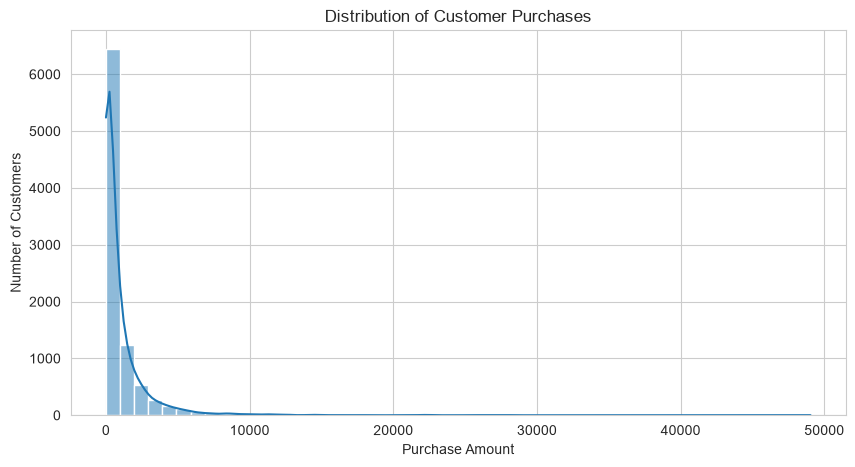

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='PURCHASES',
    bins=50,
    kde=True
)

plt.title('Distribution of Customer Purchases')
plt.xlabel('Purchase Amount')
plt.ylabel('Number of Customers')

plt.show()

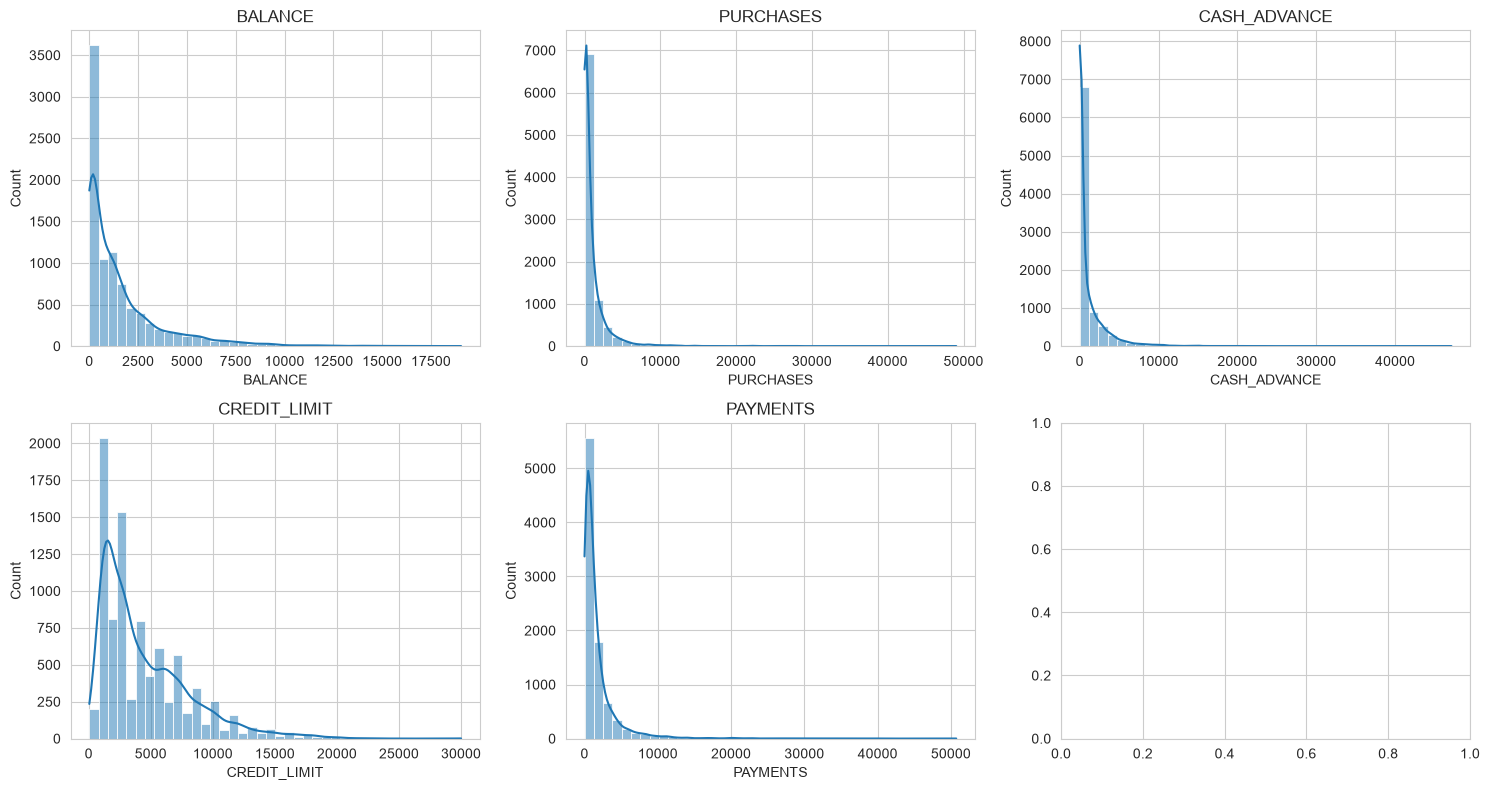

In [12]:
features = [
    'BALANCE',
    'PURCHASES',
    'CASH_ADVANCE',
    'CREDIT_LIMIT',
    'PAYMENTS'
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, feature in enumerate(features):
    sns.histplot(
        df[feature],
        bins=40,
        kde=True,
        ax=axes[i//3, i%3]
    )

    axes[i//3, i%3].set_title(feature)

plt.tight_layout()
plt.show()

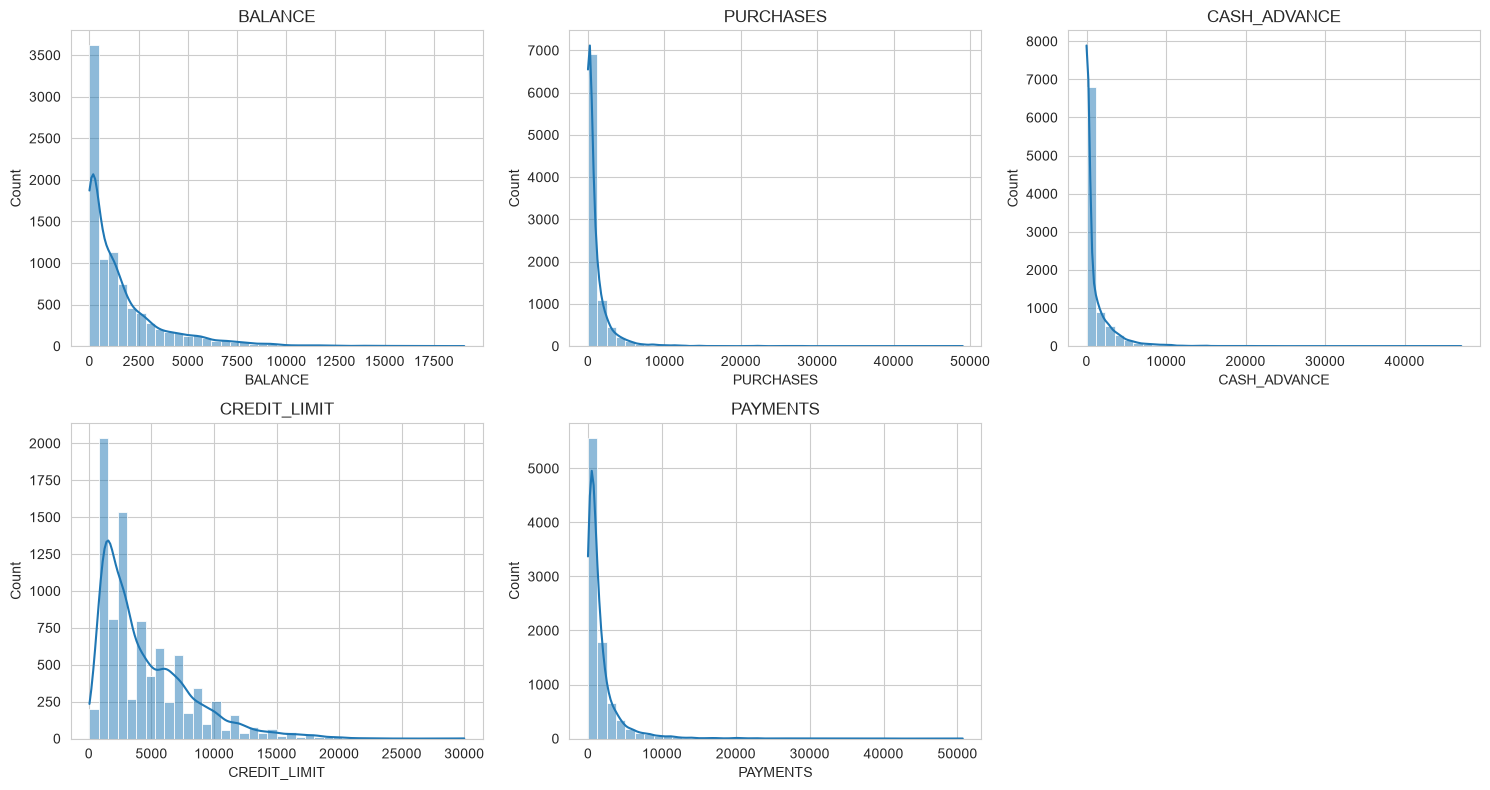

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, feature in enumerate(features):
    sns.histplot(
        df[feature],
        bins=40,
        kde=True,
        ax=axes[i//3, i%3]
    )

    axes[i//3, i%3].set_title(feature)

axes[1, 2].set_visible(False)

plt.tight_layout()
plt.show()

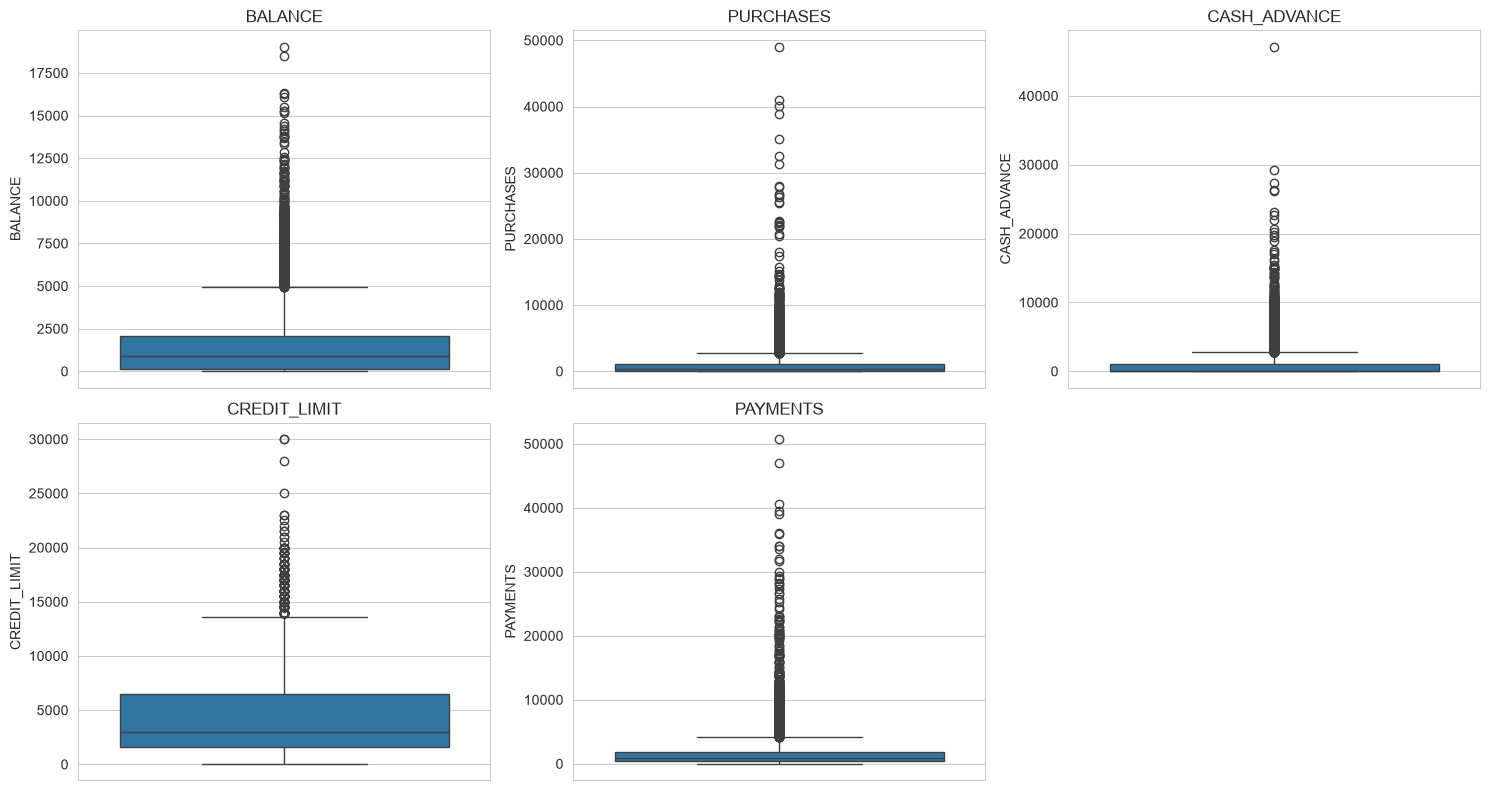

In [14]:
features = [
    'BALANCE',
    'PURCHASES',
    'CASH_ADVANCE',
    'CREDIT_LIMIT',
    'PAYMENTS'
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, feature in enumerate(features):
    sns.boxplot(
        y=df[feature],
        ax=axes[i//3, i%3]
    )

    axes[i//3, i%3].set_title(feature)

axes[1, 2].set_visible(False)

plt.tight_layout()
plt.show()

In [15]:
for feature in features:

    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower) |
        (df[feature] > upper)
    ]

    print(feature, ":", len(outliers), "potential outliers")

BALANCE : 695 potential outliers
PURCHASES : 808 potential outliers
CASH_ADVANCE : 1030 potential outliers
CREDIT_LIMIT : 248 potential outliers
PAYMENTS : 808 potential outliers


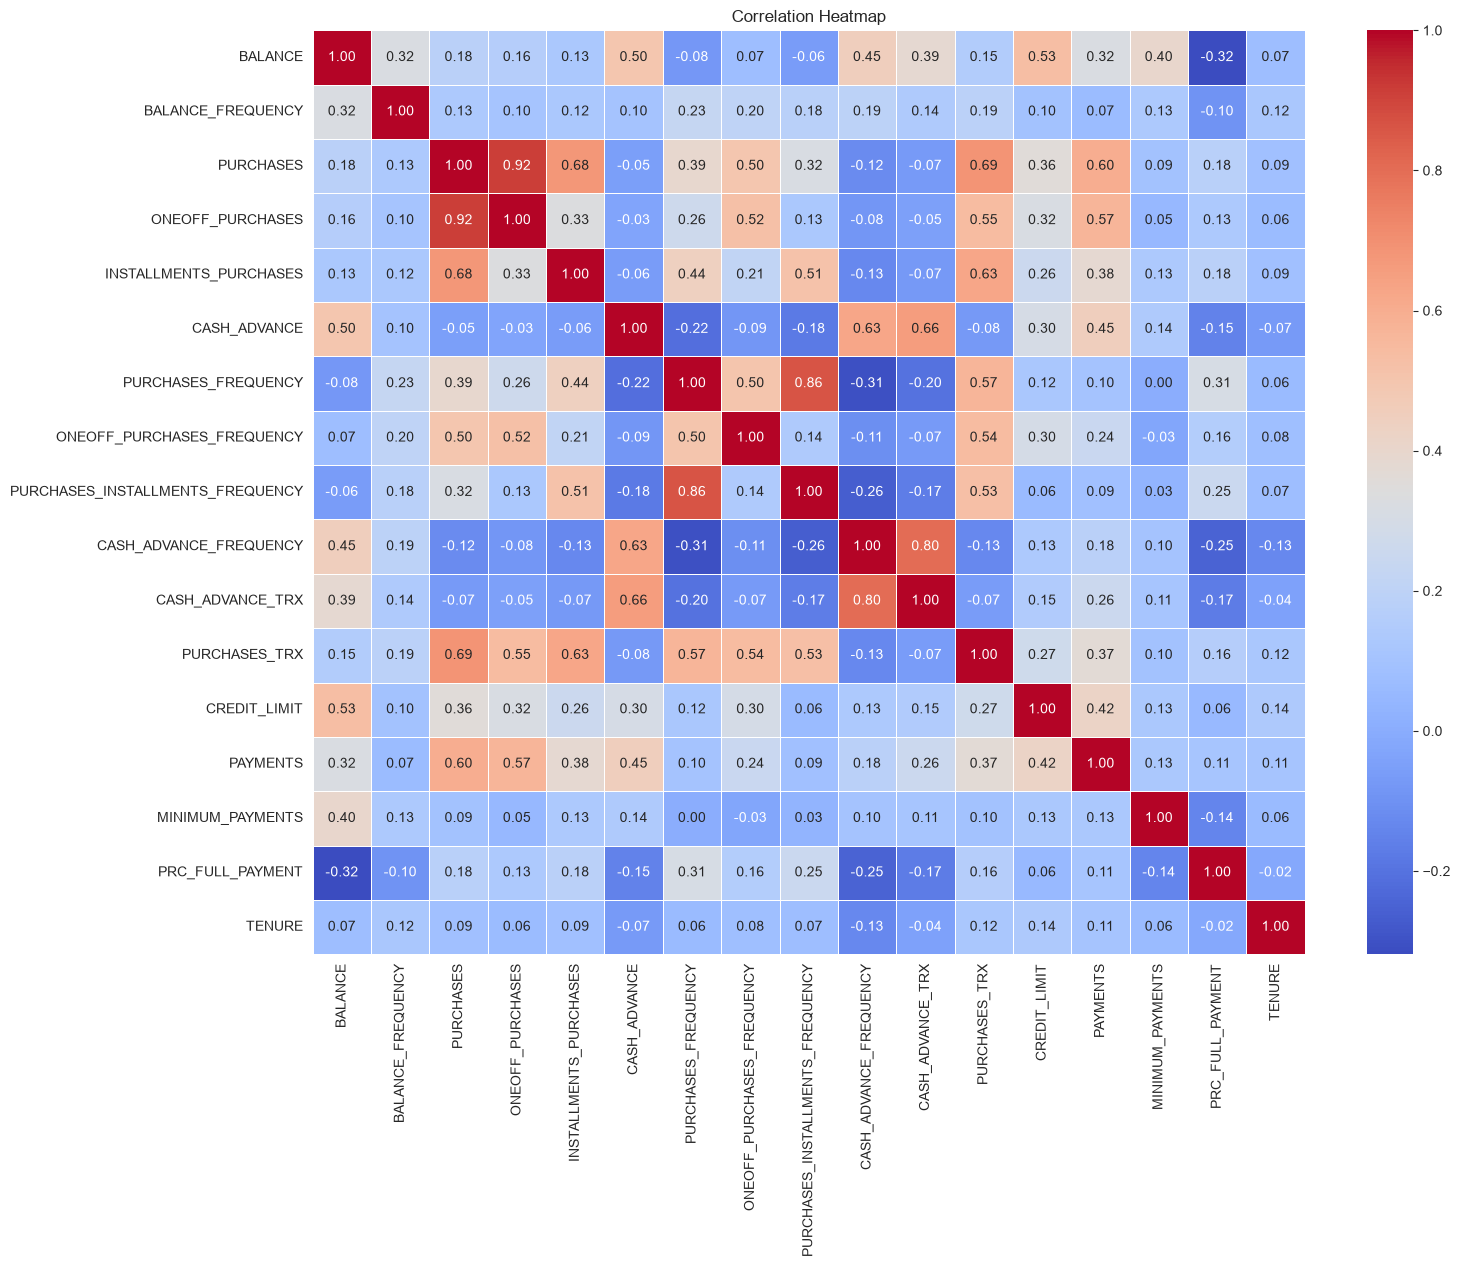

In [16]:
plt.figure(figsize=(16, 12))

corr = df.drop(columns=['CUST_ID']).corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

## EDA Conclusions

1. Dataset contains 8,950 customers and 18 columns.
2. No duplicate records were found.
3. Missing values exist in CREDIT_LIMIT and MINIMUM_PAYMENTS.
4. Financial features exhibit right-skewed distributions.
5. Several features contain potential outliers.
6. Zero values represent legitimate customer behaviour.
7. Some features exhibit strong positive correlations.
8. Log transformation and feature scaling may improve clustering.

In [17]:
import pandas as pd

df = pd.read_csv("../data/credit_card.csv")

features = [
    "BALANCE", "BALANCE_FREQUENCY", "PURCHASES",
    "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES",
    "CASH_ADVANCE", "PURCHASES_FREQUENCY",
    "ONEOFF_PURCHASES_FREQUENCY",
    "PURCHASES_INSTALLMENTS_FREQUENCY",
    "CASH_ADVANCE_FREQUENCY", "CASH_ADVANCE_TRX",
    "PURCHASES_TRX", "CREDIT_LIMIT", "PAYMENTS",
    "MINIMUM_PAYMENTS", "PRC_FULL_PAYMENT", "TENURE"
]

test_data = df[features].copy()
test_data = test_data.fillna(test_data.median())

test_data.to_csv("../data/prediction_test.csv", index=False)

print(test_data.shape)
print(test_data.isnull().sum().sum())

(8950, 17)
0
